In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

plt.style.use("default")

print("Libraries imported successfully! 🎬")

Libraries imported successfully! 🎬


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving netflix_titles.csv to netflix_titles.csv


In [ ]:
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (8807, 12)


In [ ]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s8807,Movie,Zubaan,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


Missing values

In [ ]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": (missing/len(df))*100
})

missing_df.sort_values("Percentage", ascending=False)

,Missing Values,Percentage
director,2634,29.908028
country,831,9.435676
cast,825,9.367549
date_added,10,0.113546
rating,4,0.045418
duration,3,0.034064
show_id,0,0.000000
type,0,0.000000
title,0,0.000000
release_year,0,0.000000


Data cleaning

In [ ]:
# Convert date column
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

# Fill missing text values
text_columns = [
    "director",
    "cast",
    "country",
    "rating"
]

for col in text_columns:
    df[col] = df[col].fillna("Unknown")

# Remove rows missing essential information
df = df.dropna(subset=["title", "listed_in"])

print("Remaining missing values:")
print(df.isnull().sum())

Remaining missing values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      98
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64


Movies vs TV shows

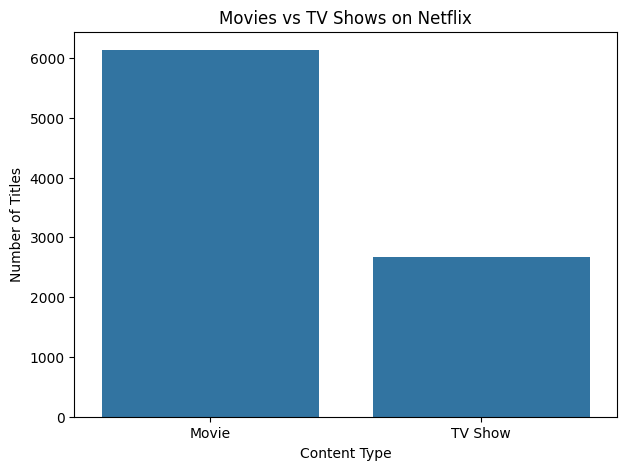

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="type"
)

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.show()

Top Genres

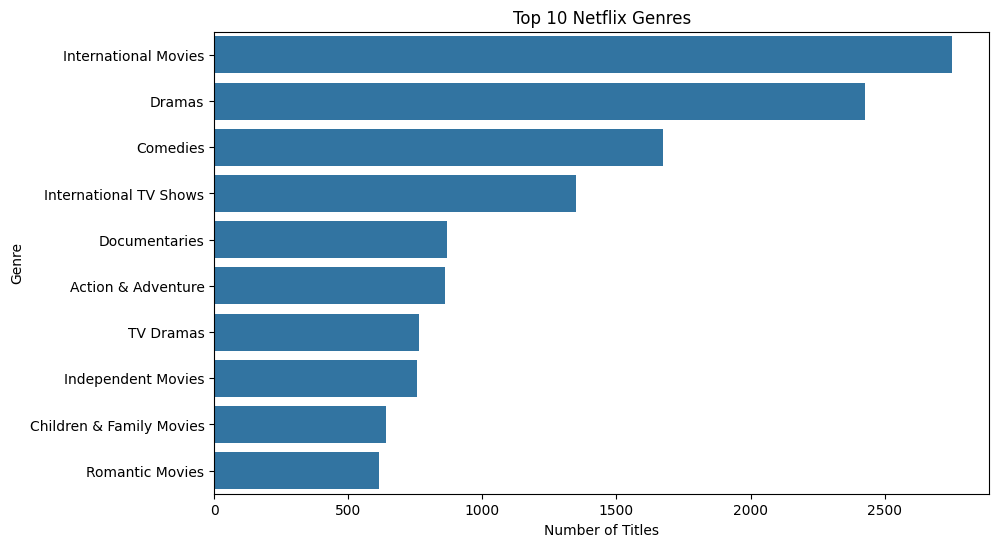

In [ ]:
genres = (
    df["listed_in"]
    .str.split(", ")
    .explode()
)

top_genres = genres.value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

Top countries

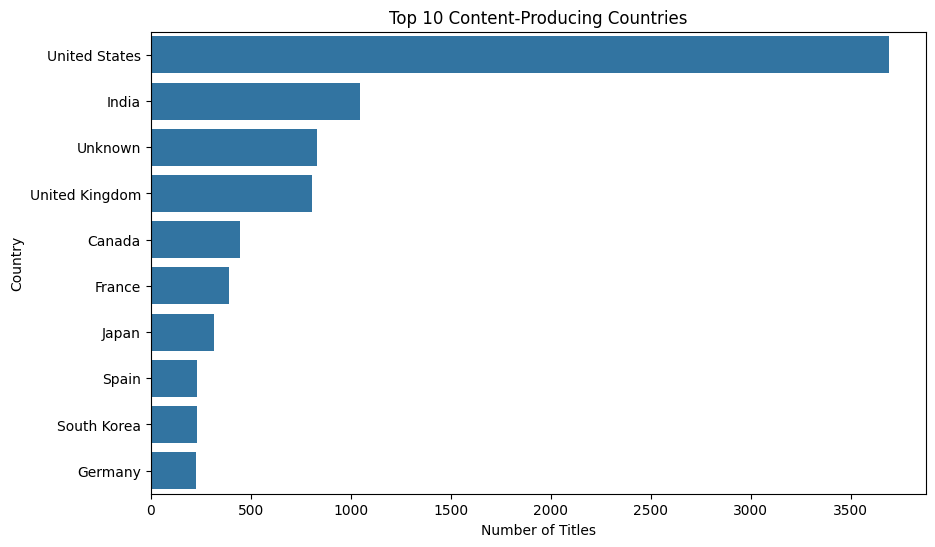

In [ ]:
countries = (
    df["country"]
    .str.split(", ")
    .explode()
)

top_countries = countries.value_counts().head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Content-Producing Countries")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.show()

Growth of Netflix over time

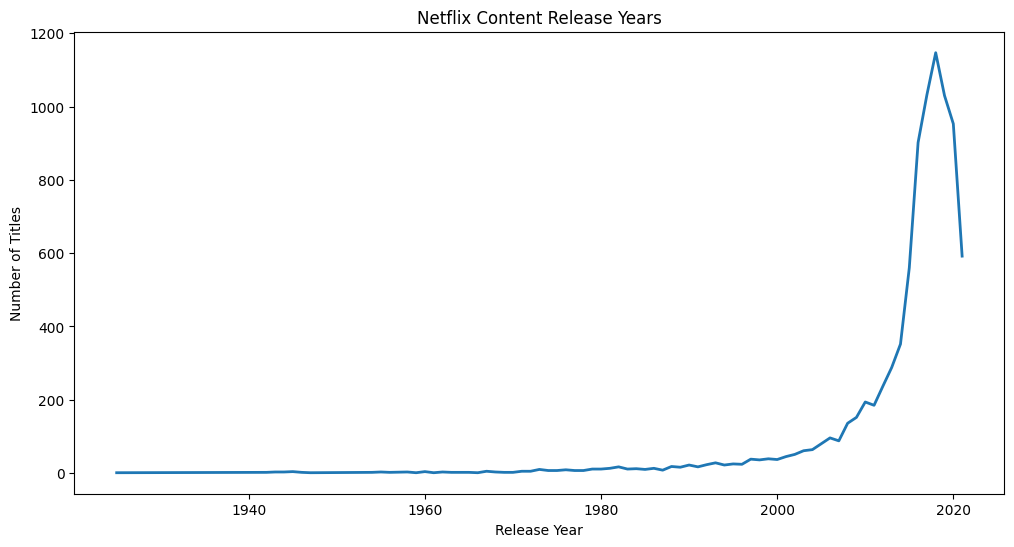

In [ ]:
content_by_year = (
    df["release_year"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12,6))

plt.plot(
    content_by_year.index,
    content_by_year.values,
    linewidth=2
)

plt.title("Netflix Content Release Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

Content ratings

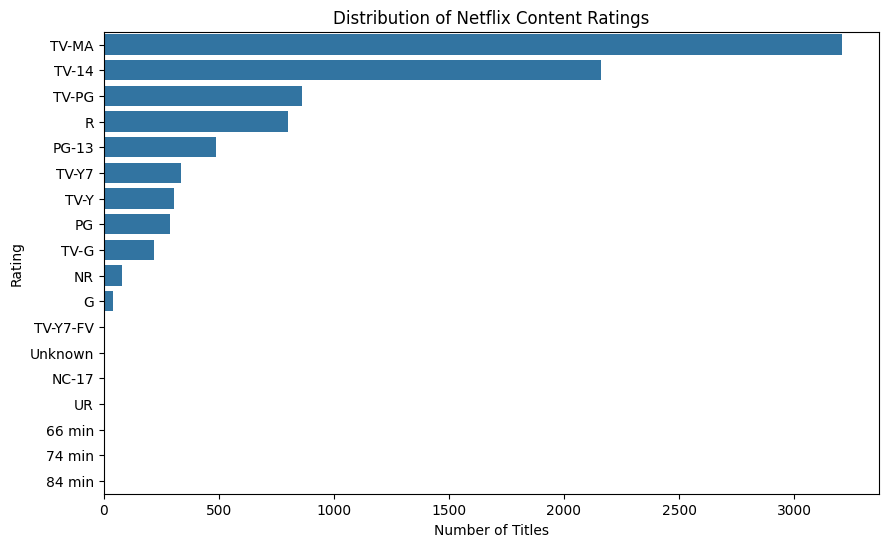

In [ ]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y="rating",
    order=df["rating"].value_counts().index
)

plt.title("Distribution of Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")

plt.show()

[Feature engineering] Extract Year and Month Added

In [ ]:
df["Year_Added"] = df["date_added"].dt.year
df["Month_Added"] = df["date_added"].dt.month

print(df[["date_added", "Year_Added", "Month_Added"]].head())

  date_added  Year_Added  Month_Added
0 2021-09-25      2021.0          9.0
1 2021-09-24      2021.0          9.0
2 2021-09-24      2021.0          9.0
3 2021-09-24      2021.0          9.0
4 2021-09-24      2021.0          9.0


Content age creation

In [ ]:
df["Content_Age"] = df["Year_Added"] - df["release_year"]

print(df[["title", "release_year", "Year_Added", "Content_Age"]].head())

                   title  release_year  Year_Added  Content_Age
0   Dick Johnson Is Dead          2020      2021.0          1.0
1          Blood & Water          2021      2021.0          0.0
2              Ganglands          2021      2021.0          0.0
3  Jailbirds New Orleans          2021      2021.0          0.0
4           Kota Factory          2021      2021.0          0.0


How quickly does netflix add content

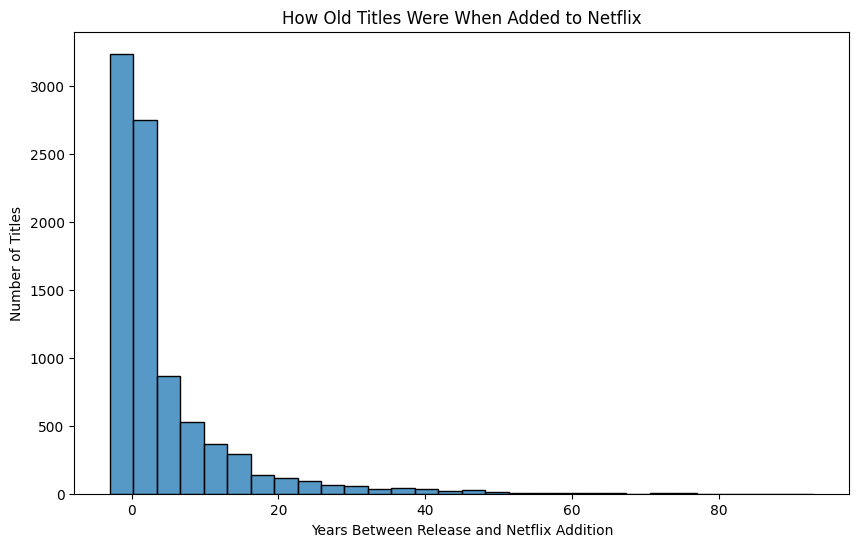

In [ ]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="Content_Age",
    bins=30
)

plt.title("How Old Titles Were When Added to Netflix")
plt.xlabel("Years Between Release and Netflix Addition")
plt.ylabel("Number of Titles")

plt.show()

Which Months Get the Most New Content?

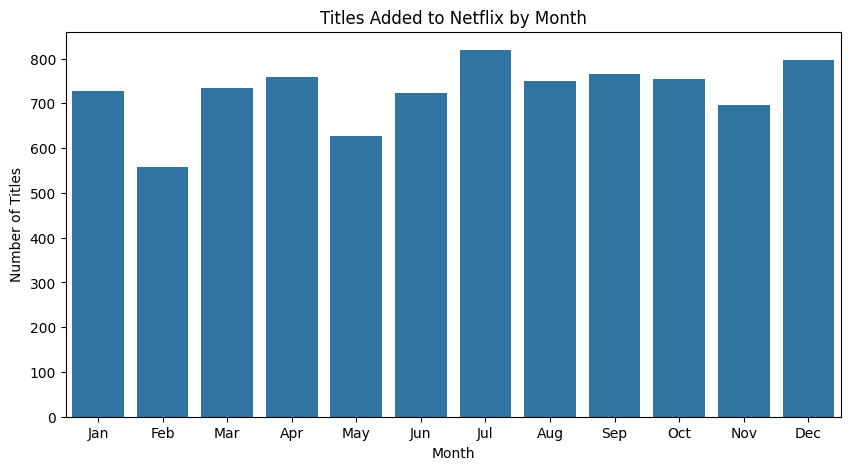

In [ ]:
month_names = {
    1:"Jan",2:"Feb",3:"Mar",4:"Apr",
    5:"May",6:"Jun",7:"Jul",8:"Aug",
    9:"Sep",10:"Oct",11:"Nov",12:"Dec"
}

monthly = (
    df["Month_Added"]
    .value_counts()
    .sort_index()
)

monthly.index = monthly.index.map(month_names)

plt.figure(figsize=(10,5))

sns.barplot(
    x=monthly.index,
    y=monthly.values
)

plt.title("Titles Added to Netflix by Month")
plt.xlabel("Month")
plt.ylabel("Number of Titles")

plt.show()

Convert Movie Duration into Numbers

In [ ]:
movies = df[df["type"] == "Movie"].copy()

movies["Duration_Minutes"] = pd.to_numeric(
    movies["duration"].str.replace(" min", "", regex=False),
    errors="coerce"
)

# Remove movies with missing duration
movies = movies.dropna(subset=["Duration_Minutes"])

# Convert to integer
movies["Duration_Minutes"] = movies["Duration_Minutes"].astype(int)

movies[["title", "duration", "Duration_Minutes"]].head()

,title,duration,Duration_Minutes
0,Dick Johnson Is Dead,90 min,90
6,My Little Pony: A New Generation,91 min,91
7,Sankofa,125 min,125
9,The Starling,104 min,104
12,Je Suis Karl,127 min,127


Movie Length Distribution

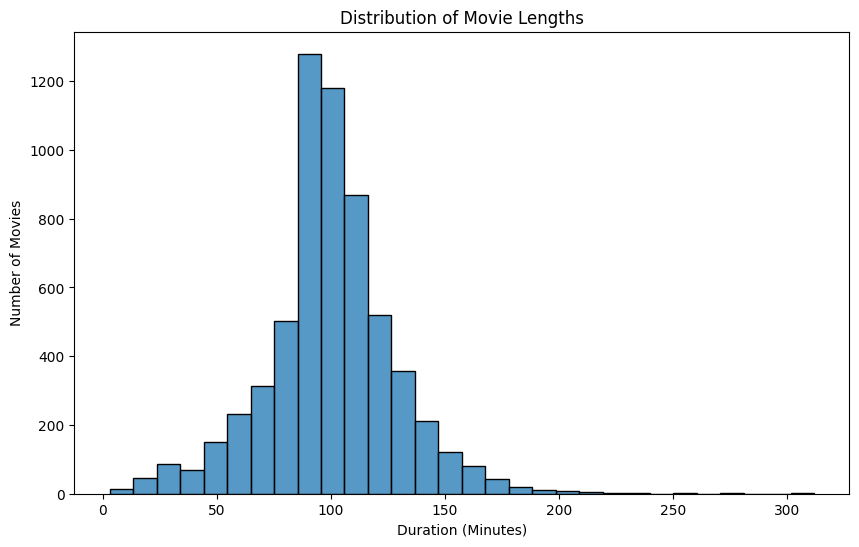

In [ ]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=movies,
    x="Duration_Minutes",
    bins=30
)

plt.title("Distribution of Movie Lengths")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")

plt.show()

**ML MODEL**

In [ ]:
ml_df = df[
    [
        "type",
        "release_year",
        "Content_Age",
        "Month_Added",
        "rating",
        "country",
        "listed_in"
    ]
].copy()

ml_df.head()

,type,release_year,Content_Age,Month_Added,rating,country,listed_in
0,Movie,2020,1.0,9.0,PG-13,United States,Documentaries
1,TV Show,2021,0.0,9.0,TV-MA,South Africa,"International TV Shows, TV Dramas, TV Mysteries"
2,TV Show,2021,0.0,9.0,TV-MA,Unknown,"Crime TV Shows, International TV Shows, TV Act..."
3,TV Show,2021,0.0,9.0,TV-MA,Unknown,"Docuseries, Reality TV"
4,TV Show,2021,0.0,9.0,TV-MA,India,"International TV Shows, Romantic TV Shows, TV ..."


Handle Missing Values

In [ ]:
ml_df["Content_Age"] = ml_df["Content_Age"].fillna(
    ml_df["Content_Age"].median()
)

ml_df["Month_Added"] = ml_df["Month_Added"].fillna(
    ml_df["Month_Added"].median()
)

for col in ["rating","country","listed_in"]:
    ml_df[col] = ml_df[col].fillna("Unknown")

ml_df.isnull().sum()

,0
type,0
release_year,0
Content_Age,0
Month_Added,0
rating,0
country,0
listed_in,0


Encode Categories

In [ ]:
X = ml_df.drop("type", axis=1)
y = ml_df["type"]

X = pd.get_dummies(
    X,
    columns=["rating","country","listed_in"],
    drop_first=True
)

print(X.shape)

(8807, 1281)


Train/Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(7045, 1281)
(1762, 1281)


Decision Tree

In [ ]:
dt = DecisionTreeClassifier(
    max_depth=8,
    random_state=42
)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

dt_acc = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_acc)

Decision Tree Accuracy: 0.7905788876276958


Random Forest

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_acc = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_acc)

Random Forest Accuracy: 0.7338251986379115


Compare models

In [ ]:
comparison = pd.DataFrame({
    "Model":[
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy":[
        dt_acc,
        rf_acc
    ]
})

comparison

,Model,Accuracy
0,Decision Tree,0.790579
1,Random Forest,0.733825


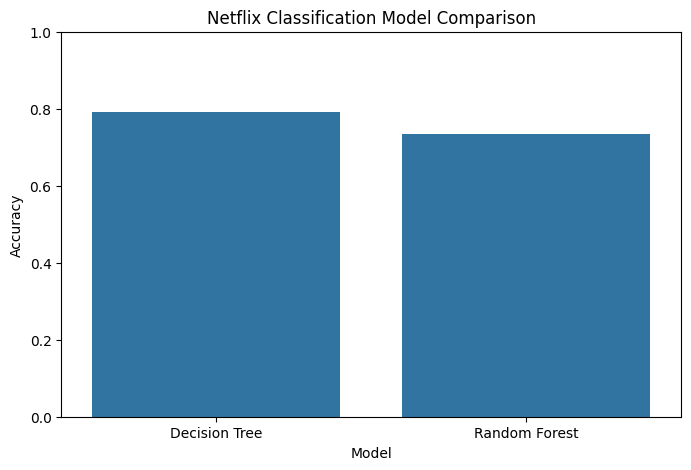

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.ylim(0,1)
plt.title("Netflix Classification Model Comparison")

plt.show()

Classification Reports

In [ ]:
print("Decision Tree Classification Report")
print(classification_report(y_test, dt_pred))

print("\nRandom Forest Classification Report")
print(classification_report(y_test, rf_pred))

Decision Tree Classification Report
              precision    recall  f1-score   support

       Movie       0.85      0.86      0.85      1227
     TV Show       0.66      0.64      0.65       535

    accuracy                           0.79      1762
   macro avg       0.75      0.75      0.75      1762
weighted avg       0.79      0.79      0.79      1762


Random Forest Classification Report
              precision    recall  f1-score   support

       Movie       0.72      1.00      0.84      1227
     TV Show       1.00      0.12      0.22       535

    accuracy                           0.73      1762
   macro avg       0.86      0.56      0.53      1762
weighted avg       0.81      0.73      0.65      1762



Random Forest Confusion Matrix

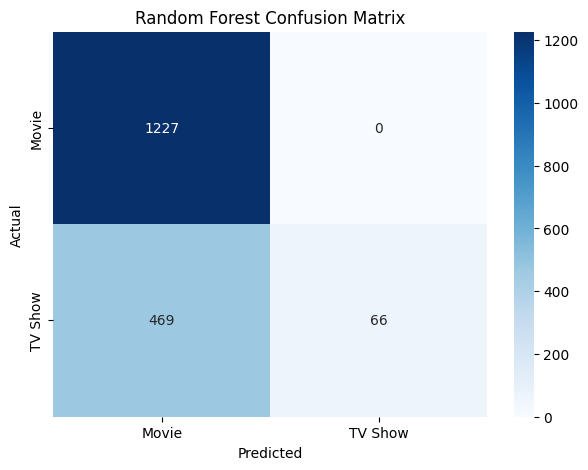

In [ ]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Movie","TV Show"],
    yticklabels=["Movie","TV Show"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Feature Importance

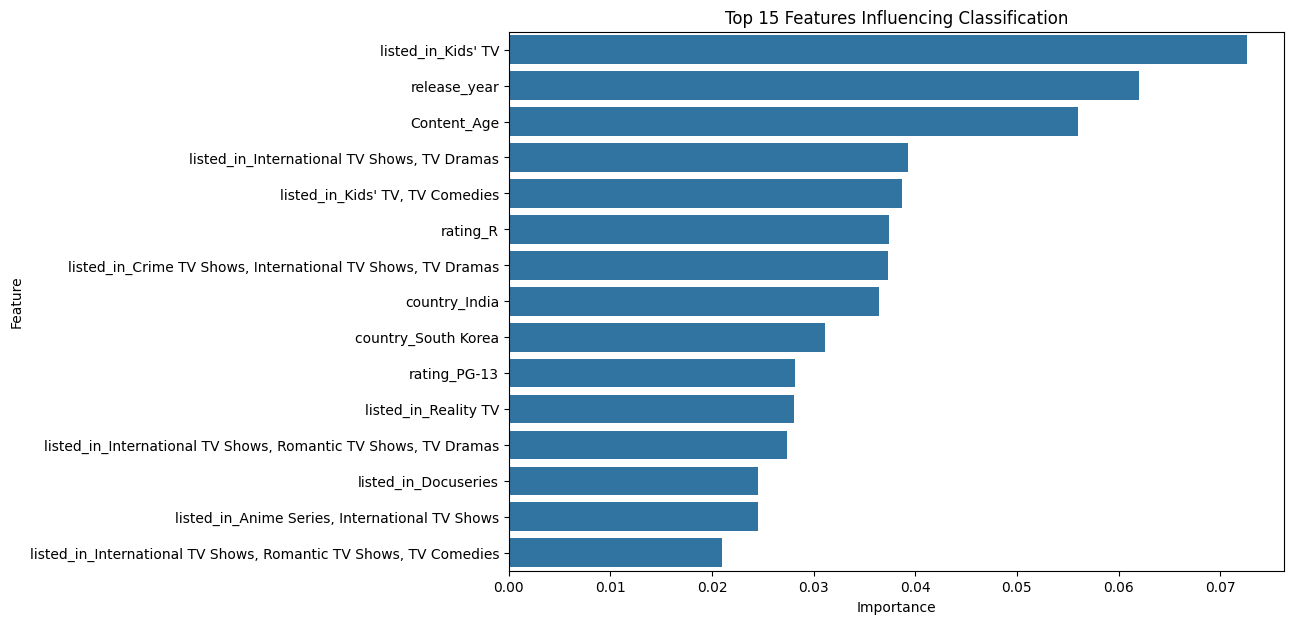

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

top15 = importance.head(15)

plt.figure(figsize=(10,7))

sns.barplot(
    data=top15,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Classification")

plt.show()

Example Prediction

In [ ]:
example = X_test.iloc[[0]]

prediction = rf.predict(example)[0]

print("Predicted content type:", prediction)
print("Actual content type:", y_test.iloc[0])

Predicted content type: Movie
Actual content type: Movie
